# Sales Demand Forecasting & Inventory Optimization Pipeline

**Domain:** Applied Mathematics, Informatics & Data Science  
**Technical Stack:** Python, Skforecast, XGBoost, Pandas, Matplotlib, Statsmodels, SciPy / Monte Carlo Simulation

## 1. Project Introduction & Business Objective
Imbalances between supply and demand lead to substantial operational inefficiencies in retail supply chains:
- **Excess Inventory:** Increases holding and capital storage costs.
- **Stockouts:** Result in unfulfilled orders and lost revenue.

This project builds an end-to-end **Data Science & Operations Research** pipeline to:
1. **Forecast weekly sales demand** across store networks using an advanced recursive time-series model (`XGBoost` via `Skforecast`).
2. **Incorporate exogenous covariates** (temperature, holiday indicators, economic factors such as CPI and unemployment rates).
3. **Optimize inventory replenishment ($Q^*$) and safety stock levels** using a Monte Carlo stochastic simulation, minimizing expected operational costs while maintaining high service levels.

In [1]:
!pip install kagglehub

## 2. Data Ingestion & Data Cleaning
We integrate three datasets from the *Walmart Recruiting - Store Sales Forecasting* challenge:
- **Sales History (`train.csv`):** Weekly historical sales aggregated by store and department.
- **External Features (`features.csv`):** Macroeconomic, environmental, and promotional indicators (`MarkDown` values).
- **Store Attributes (`stores.csv`):** Physical store types and square footage sizes.

In [2]:
import kagglehub
import pandas as pd
import os

In [3]:
path = kagglehub.dataset_download("ducnguyen168/walmart-recruiting-store-sales-forecasting-thpt")
print("Path to dataset files:", path)

Path to dataset files: /Users/sarasbati/.cache/kagglehub/datasets/ducnguyen168/walmart-recruiting-store-sales-forecasting-thpt/versions/1


In [4]:
data_dir = os.path.join(path, "walmart-recruiting-store-sales-forecasting")

In [5]:
train_df = pd.read_csv(os.path.join(data_dir, "train.csv"))
features_df = pd.read_csv(os.path.join(data_dir, "features.csv"))
stores_df = pd.read_csv(os.path.join(data_dir, "stores.csv"))

In [6]:
train_df.head()   

,Store,Dept,Date,Weekly_Sales,IsHoliday
0,1,1,2010-02-05,24924.50,False
1,1,1,2010-02-12,46039.49,True
2,1,1,2010-02-19,41595.55,False
3,1,1,2010-02-26,19403.54,False
4,1,1,2010-03-05,21827.90,False


In [7]:
features_df.head()   

,Store,Date,Temperature,Fuel_Price,MarkDown1,MarkDown2,MarkDown3,MarkDown4,MarkDown5,CPI,Unemployment,IsHoliday
0,1,2010-02-05,42.31,2.572,NaN,NaN,NaN,NaN,NaN,211.096358,8.106,False
1,1,2010-02-12,38.51,2.548,NaN,NaN,NaN,NaN,NaN,211.242170,8.106,True
2,1,2010-02-19,39.93,2.514,NaN,NaN,NaN,NaN,NaN,211.289143,8.106,False
3,1,2010-02-26,46.63,2.561,NaN,NaN,NaN,NaN,NaN,211.319643,8.106,False
4,1,2010-03-05,46.50,2.625,NaN,NaN,NaN,NaN,NaN,211.350143,8.106,False


In [8]:
stores_df.head()

,Store,Type,Size
0,1,A,151315
1,2,A,202307
2,3,B,37392
3,4,A,205863
4,5,B,34875


In [9]:
train_df.shape

(421570, 5)

In [10]:
features_df.shape

(8190, 12)

In [11]:
stores_df.shape

(45, 3)

In [12]:
df = train_df.merge(stores_df, on='Store', how='left')
df = df.merge(features_df, on=['Store', 'Date'], how='left')

In [13]:
df.head()

,Store,Dept,Date,Weekly_Sales,IsHoliday_x,Type,Size,Temperature,Fuel_Price,MarkDown1,MarkDown2,MarkDown3,MarkDown4,MarkDown5,CPI,Unemployment,IsHoliday_y
0,1,1,2010-02-05,24924.50,False,A,151315,42.31,2.572,NaN,NaN,NaN,NaN,NaN,211.096358,8.106,False
1,1,1,2010-02-12,46039.49,True,A,151315,38.51,2.548,NaN,NaN,NaN,NaN,NaN,211.242170,8.106,True
2,1,1,2010-02-19,41595.55,False,A,151315,39.93,2.514,NaN,NaN,NaN,NaN,NaN,211.289143,8.106,False
3,1,1,2010-02-26,19403.54,False,A,151315,46.63,2.561,NaN,NaN,NaN,NaN,NaN,211.319643,8.106,False
4,1,1,2010-03-05,21827.90,False,A,151315,46.50,2.625,NaN,NaN,NaN,NaN,NaN,211.350143,8.106,False


### Preprocessing & Cleaning Steps:
- Replaced missing values (`NaN`) in promotional markdown columns (`MarkDown1-5`) with `0`.
- Filtered out anomalous non-positive weekly sales values ($Sales \le 0$).
- Converted date features to standard `datetime` formats and extracted temporal components (Year, Month, Week of Year).

In [14]:
markdown_cols = ['MarkDown1', 'MarkDown2', 'MarkDown3', 'MarkDown4', 'MarkDown5']
df[markdown_cols] = df[markdown_cols].fillna(0)

In [15]:
df = df[df['Weekly_Sales'] > 0]

In [16]:
df['Date'] = pd.to_datetime(df['Date'])
df['Year'] = df['Date'].dt.year
df['Month'] = df['Date'].dt.month
df['Week'] = df['Date'].dt.isocalendar().week

In [17]:
df.head()

,Store,Dept,Date,Weekly_Sales,IsHoliday_x,Type,Size,Temperature,Fuel_Price,MarkDown1,MarkDown2,MarkDown3,MarkDown4,MarkDown5,CPI,Unemployment,IsHoliday_y,Year,Month,Week
0,1,1,2010-02-05,24924.50,False,A,151315,42.31,2.572,0.0,0.0,0.0,0.0,0.0,211.096358,8.106,False,2010,2,5
1,1,1,2010-02-12,46039.49,True,A,151315,38.51,2.548,0.0,0.0,0.0,0.0,0.0,211.242170,8.106,True,2010,2,6
2,1,1,2010-02-19,41595.55,False,A,151315,39.93,2.514,0.0,0.0,0.0,0.0,0.0,211.289143,8.106,False,2010,2,7
3,1,1,2010-02-26,19403.54,False,A,151315,46.63,2.561,0.0,0.0,0.0,0.0,0.0,211.319643,8.106,False,2010,2,8
4,1,1,2010-03-05,21827.90,False,A,151315,46.50,2.625,0.0,0.0,0.0,0.0,0.0,211.350143,8.106,False,2010,3,9


In [18]:
differences = df.groupby('Store')['Date'].apply(lambda x: x.drop_duplicates().sort_values().diff().dt.days)
print("Differences in days between consecutive dates, by store:")
print(differences.value_counts())

Differences in days between consecutive dates, by store:
Date
7.0    6390
Name: count, dtype: int64


In [19]:
unique_dates = df['Date'].drop_duplicates().sort_values()
differences_days = unique_dates.diff().dt.days.value_counts()
print("Differences in days between consecutive dates:")
print(differences_days)

Differences in days between consecutive dates:
Date
7.0    142
Name: count, dtype: int64


In [20]:
print(df.isna().sum())

Store           0
Dept            0
Date            0
Weekly_Sales    0
IsHoliday_x     0
Type            0
Size            0
Temperature     0
Fuel_Price      0
MarkDown1       0
MarkDown2       0
MarkDown3       0
MarkDown4       0
MarkDown5       0
CPI             0
Unemployment    0
IsHoliday_y     0
Year            0
Month           0
Week            0
dtype: int64


In [21]:
df['CPI'] = df.groupby('Store')['CPI'].ffill().bfill()   
df['Unemployment'] = df.groupby('Store')['Unemployment'].ffill().bfill()

In [22]:
df['IsHoliday_y'] = df['IsHoliday_y'].astype(int)  

In [23]:
df = df.sort_values(by='Date')

In [24]:
df.head()

,Store,Dept,Date,Weekly_Sales,IsHoliday_x,Type,Size,Temperature,Fuel_Price,MarkDown1,MarkDown2,MarkDown3,MarkDown4,MarkDown5,CPI,Unemployment,IsHoliday_y,Year,Month,Week
0,1,1,2010-02-05,24924.50,False,A,151315,42.31,2.572,0.0,0.0,0.0,0.0,0.0,211.096358,8.106,0,2010,2,5
140804,15,21,2010-02-05,3253.19,False,B,123737,19.83,2.954,0.0,0.0,0.0,0.0,0.0,131.527903,8.350,0,2010,2,5
140661,15,20,2010-02-05,4606.90,False,B,123737,19.83,2.954,0.0,0.0,0.0,0.0,0.0,131.527903,8.350,0,2010,2,5
140518,15,19,2010-02-05,1381.40,False,B,123737,19.83,2.954,0.0,0.0,0.0,0.0,0.0,131.527903,8.350,0,2010,2,5
140408,15,18,2010-02-05,2239.25,False,B,123737,19.83,2.954,0.0,0.0,0.0,0.0,0.0,131.527903,8.350,0,2010,2,5


## 3. Exploratory Data Analysis (EDA) & Time Series Aggregation
We aggregate total sales across the entire store network to form a unified weekly time series (`df_weekly`). This allows us to analyze macroeconomic trends, variance, and underlying seasonality.

In [25]:
df_weekly = df.groupby('Date')['Weekly_Sales'].sum().reset_index()

In [26]:
df_weekly.head()

,Date,Weekly_Sales
0,2010-02-05,49750875.98
1,2010-02-12,48336800.10
2,2010-02-19,48277902.33
3,2010-02-26,43970440.65
4,2010-03-05,46872715.16


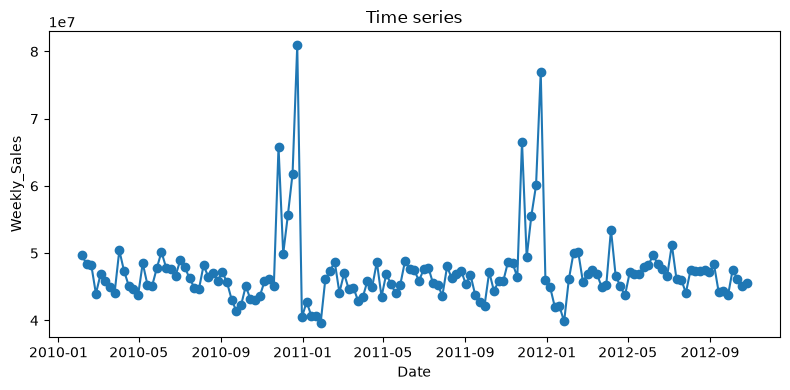

In [27]:
import matplotlib.pyplot as plt
plt.figure(figsize=(8,4))
plt.plot(df_weekly['Date'], df_weekly['Weekly_Sales'],marker="o")
plt.title("Time series")
plt.xlabel("Date")
plt.ylabel("Weekly_Sales")
plt.tight_layout()
plt.show()

### 3.1. Autocorrelation & Partial Autocorrelation Analysis (ACF & PACF)
To understand the autoregressive structure of the time series, we evaluate the **Autocorrelation Function (ACF)** and **Partial Autocorrelation Function (PACF)** up to 52 weekly lags.

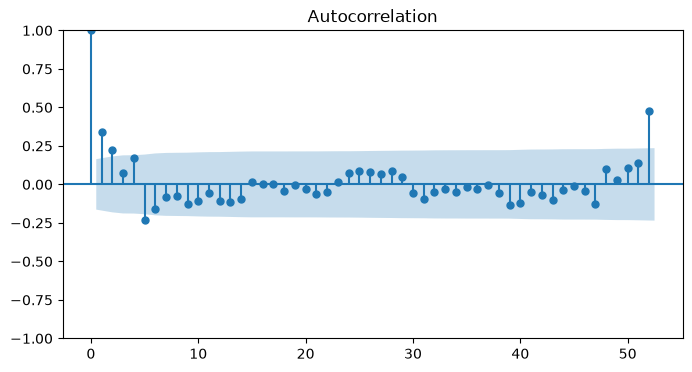

In [29]:
from statsmodels.graphics.tsaplots import plot_acf, plot_pacf
fig, ax = plt.subplots(figsize=(8, 4))
plot_acf(df_weekly['Weekly_Sales'], ax=ax, lags=52, fft=True)
plt.show()

* **Key Finding:** A statistically significant spike emerges precisely at Lag 52, confirming strong annual seasonality driven by recurring seasonal shopping peaks. Consequently, we configure our autoregressive forecasting window with $52$ lags.

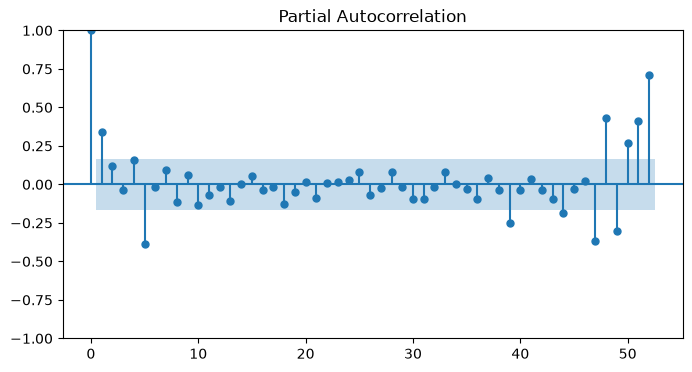

In [30]:
fig, ax = plt.subplots(figsize=(8, 4))
plot_pacf(df_weekly['Weekly_Sales'], ax=ax, lags=52, method='burg')
plt.show()

In [31]:
from skforecast.stats import calculate_lag_autocorrelation
calculate_lag_autocorrelation(
    data        = df_weekly['Weekly_Sales'],
    n_lags      = 52,
    sort_by     = 'partial_autocorrelation_abs'
).head(10)

,lag,partial_autocorrelation_abs,partial_autocorrelation,autocorrelation_abs,autocorrelation
0,5,0.384523,-0.384523,0.231917,-0.231917
1,1,0.337427,0.337427,0.337427,0.337427
2,51,0.204461,0.204461,0.136746,0.136746
3,39,0.200402,-0.200402,0.130824,-0.130824
4,47,0.196602,-0.196602,0.127388,-0.127388
5,48,0.194980,0.194980,0.101095,0.101095
6,52,0.173789,0.173789,0.478828,0.478828
7,49,0.171038,-0.171038,0.027690,0.027690
8,4,0.155930,0.155930,0.173844,0.173844
9,10,0.135384,-0.135384,0.105928,-0.105928


## 4. Time Series Forecasting Engine 
We construct a recursive autoregressive model (`ForecasterRecursive`) powered by `XGBRegressor`. The model incorporates:
- 52 historical weekly lags.
- Rolling window statistical features (4-week rolling mean and standard deviation).

In [32]:
import xgboost
import skforecast
from xgboost import XGBRegressor
from skforecast.recursive import ForecasterRecursive
from skforecast.preprocessing import RollingFeatures

In [33]:
window_features = RollingFeatures(stats=['mean', 'std'], window_sizes = 4)
forecaster = ForecasterRecursive(
    estimator            = XGBRegressor(tree_method='hist', random_state=15926),
    lags                 = 52,  
    window_features      = window_features,
    categorical_features = 'auto'
)

In [34]:
print("Start of the dataset:", df_weekly.index.min())
print("End of the dataset:", df_weekly.index.max())

Start of the dataset: 0
End of the dataset: 142


In [35]:
end_train = 100
end_validation = 120
forecaster.fit(y=df_weekly.loc[:end_validation, 'Weekly_Sales'])
forecaster

=================== 
ForecasterRecursive 
=================== 
Estimator: XGBRegressor 
Lags: [ 1  2  3  4  5  6  7  8  9 10 11 12 13 14 15 16 17 18 19 20 21 22 23 24
 25 26 27 28 29 30 31 32 33 34 35 36 37 38 39 40 41 42 43 44 45 46 47 48
 49 50 51 52] 
Window features: ['roll_mean_4', 'roll_std_4'] 
Calendar features: None 
Window size: 52 
Series name: Weekly_Sales 
Exogenous included: False 
Exogenous names: None 
Categorical features: auto 
Transformer for y: None 
Transformer for exog: None 
Weight function included: False 
Differentiation order: None 
Drop NaN from series: False 
Training range: [0, 120] 
Training index type: RangeIndex 
Training index frequency: 1 
Estimator parameters: 
    {'objective': 'reg:squarederror', 'base_score': None, 'booster': None,
    'callbacks': None, 'colsample_bylevel': None, 'colsample_bynode': None,
    'colsample_bytree': None, 'device': None, 'early_stopping_rounds': None,
    'enable_categorical': False, 'eval_metric': None, 'feature_types': None,
    'feature_weights': None, 'gamma': None, 'grow_policy': None,
    'importance_type': None, 'interaction_constraints': None, 'learning_rate':
    None, 'max_bin': None, 'max_cat_threshold': None, 'max_cat_to_onehot': None,
    'max_delta_step': None, 'max_depth': None, 'max_leaves': None,
    'min_child_weight': None, 'missing': nan, 'monotone_constraints': None,
    'multi_strategy': None, 'n_estimators': None, 'n_jobs': None,
    'num_parallel_tree': None, 'random_state': 15926, 'reg_alpha': None,
    'reg_lambda': None, 'sampling_method': None, 'scale_pos_weight': None,
    'subsample': None, 'tree_method': 'hist', 'validate_parameters': None,
    'verbosity': None} 
fit_kwargs: {} 
Creation date: 2026-10-20 10:59:47 
Last fit date: 2026-10-20 10:59:53 
Skforecast version: 0.26.0 
Python version: 3.14.6 
Forecaster id: None

In [36]:
predictions = forecaster.predict(steps=4)   # for 4 weeks
predictions

121    47176648.0
122    47721424.0
123    48487992.0
124    48341060.0
Name: pred, dtype: float64

### Model Validation (Backtesting):
To rigorously evaluate out-of-sample performance over 4-week prediction horizons, we employ Rolling Window Backtesting (`TimeSeriesFold`).

In [37]:
from skforecast.model_selection import backtesting_forecaster, TimeSeriesFold

In [38]:
cv = TimeSeriesFold(steps = 4, initial_train_size = 120)
metric, predictions = backtesting_forecaster(
    forecaster = forecaster,
    y          = df_weekly['Weekly_Sales'],
    cv         = cv,
    metric     = 'mean_absolute_error' 
)

  0%|          | 0/6 [00:00<?, ?it/s]

In [39]:
predictions.head()

,fold,pred
120,0,45633212.0
121,0,47019808.0
122,0,47958900.0
123,0,48293172.0
124,1,47991640.0


In [40]:
print("Mean absolute error:", metric)

Mean absolute error:    mean_absolute_error
0         1.266835e+06


## 5. Integrating Exogenous Variables
We evaluate model performance improvements by incorporating macroeconomic and promotional covariates (`IsHoliday`, `Temperature`, `Fuel_Price`, `MarkDown1-5`, `CPI`, and `Unemployment`) into the `XGBoost` feature matrix.

In [41]:
df_weekly_exog = df.groupby('Date').agg({
    'Weekly_Sales': 'sum',
    'IsHoliday_x': 'max',        
    'Temperature': 'mean',       
    'Fuel_Price': 'mean',        
    'MarkDown1': 'sum',          
    'MarkDown2': 'sum',
    'MarkDown3': 'sum',
    'MarkDown4': 'sum',
    'MarkDown5': 'sum',
    'CPI': 'mean',               
    'Unemployment': 'mean'       
}).reset_index()

In [42]:
df_weekly_exog.shape

(143, 12)

In [43]:
columns_exog = ['IsHoliday_x', 'Temperature', 'Fuel_Price', 'MarkDown1', 'MarkDown2', 'MarkDown3', 'MarkDown4', 'MarkDown5', 'CPI', 'Unemployment']
forecaster.fit(
    y    = df_weekly_exog.loc[:end_validation, 'Weekly_Sales'],
    exog = df_weekly_exog.loc[:end_validation, columns_exog]
)
forecaster

=================== 
ForecasterRecursive 
=================== 
Estimator: XGBRegressor 
Lags: [ 1  2  3  4  5  6  7  8  9 10 11 12 13 14 15 16 17 18 19 20 21 22 23 24
 25 26 27 28 29 30 31 32 33 34 35 36 37 38 39 40 41 42 43 44 45 46 47 48
 49 50 51 52] 
Window features: ['roll_mean_4', 'roll_std_4'] 
Calendar features: None 
Window size: 52 
Series name: Weekly_Sales 
Exogenous included: True 
Exogenous names: 
    IsHoliday_x, Temperature, Fuel_Price, MarkDown1, MarkDown2, MarkDown3,
    MarkDown4, MarkDown5, CPI, Unemployment 
Categorical features: auto 
Transformer for y: None 
Transformer for exog: None 
Weight function included: False 
Differentiation order: None 
Drop NaN from series: False 
Training range: [0, 120] 
Training index type: RangeIndex 
Training index frequency: 1 
Estimator parameters: 
    {'objective': 'reg:squarederror', 'base_score': None, 'booster': None,
    'callbacks': None, 'colsample_bylevel': None, 'colsample_bynode': None,
    'colsample_bytree': None, 'device': None, 'early_stopping_rounds': None,
    'enable_categorical': False, 'eval_metric': None, 'feature_types': None,
    'feature_weights': None, 'gamma': None, 'grow_policy': None,
    'importance_type': None, 'interaction_constraints': None, 'learning_rate':
    None, 'max_bin': None, 'max_cat_threshold': None, 'max_cat_to_onehot': None,
    'max_delta_step': None, 'max_depth': None, 'max_leaves': None,
    'min_child_weight': None, 'missing': nan, 'monotone_constraints': None,
    'multi_strategy': None, 'n_estimators': None, 'n_jobs': None,
    'num_parallel_tree': None, 'random_state': 15926, 'reg_alpha': None,
    'reg_lambda': None, 'sampling_method': None, 'scale_pos_weight': None,
    'subsample': None, 'tree_method': 'hist', 'validate_parameters': None,
    'verbosity': None} 
fit_kwargs: {} 
Creation date: 2026-10-20 10:59:47 
Last fit date: 2026-10-20 11:00:18 
Skforecast version: 0.26.0 
Python version: 3.14.6 
Forecaster id: None

In [44]:
cv = TimeSeriesFold(steps = 4, initial_train_size = 120)
metric, predictions = backtesting_forecaster(
    forecaster = forecaster,
    y          = df_weekly_exog['Weekly_Sales'],
    exog       = df_weekly_exog[columns_exog],
    cv         = cv,
    metric     = 'mean_absolute_error'
)

  0%|          | 0/6 [00:00<?, ?it/s]

In [46]:
print("MAE with exogenous variables:", metric)
predictions.head()

MAE with exogenous variables:    mean_absolute_error
0        974508.183043


,fold,pred
120,0,45802052.0
121,0,46753304.0
122,0,48712604.0
123,0,47590888.0
124,1,47108744.0


## 6. Hyperparameter Tuning via Bayesian Search
To maximize predictive accuracy, we execute a Bayesian Hyperparameter Search (`bayesian_search_forecaster`) over the `XGBoost` parameter space (`n_estimators`, `max_depth`, `learning_rate`, `subsample`, `colsample_bytree`) alongside optimal lag selections.

In [47]:
from skforecast.model_selection import bayesian_search_forecaster

In [48]:
lags_grid = [4, 12, 26, 52]
def search_space(trial):
    return {
        'n_estimators'    : trial.suggest_int('n_estimators', 100, 800, step=100),
        'max_depth'       : trial.suggest_int('max_depth', 3, 9),
        'learning_rate'   : trial.suggest_float('learning_rate', 0.01, 0.3, log=True),
        'subsample'       : trial.suggest_float('subsample', 0.5, 1.0),
        'colsample_bytree': trial.suggest_float('colsample_bytree', 0.5, 1.0),
        'lags'            : trial.suggest_categorical('lags', lags_grid)
    }

In [49]:
cv_search = TimeSeriesFold(steps = 4, initial_train_size = end_validation)
results_search, frozen_trial = bayesian_search_forecaster(
    forecaster    = forecaster,
    y             = df_weekly_exog.loc[:end_validation, 'Weekly_Sales'],
    exog          = df_weekly_exog.loc[:end_validation, columns_exog],
    cv            = cv_search,
    search_space  = search_space,
    metric        = 'mean_absolute_error',
    n_trials      = 15,    
    return_best   = True   
)

  0%|          | 0/15 [00:00<?, ?it/s]

In [ ]:
results_search.head(3)

In [51]:
metric, predictions = backtesting_forecaster(
    forecaster = forecaster,
    y          = df_weekly_exog['Weekly_Sales'],
    exog       = df_weekly_exog[columns_exog],
    cv         = cv_search,
    metric     = 'mean_absolute_error'
)

  0%|          | 0/6 [00:00<?, ?it/s]

In [52]:
print("MAE optimized via Bayesian Search:", metric)

MAE optimized via Bayesian Search:    mean_absolute_error
0         895123.65087


In [53]:
predictions.head()

,fold,pred
120,0,47873896.0
121,0,47263012.0
122,0,47921488.0
123,0,47542676.0
124,1,48032484.0


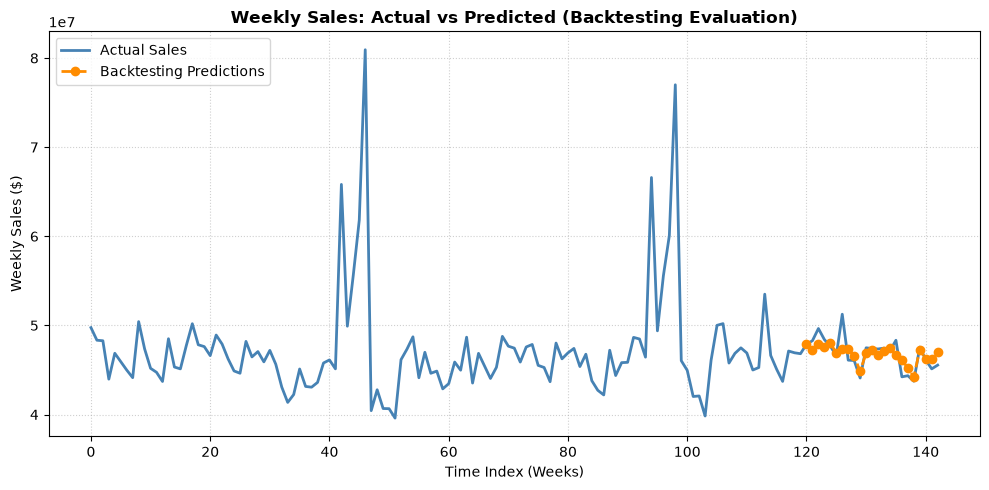

In [54]:
fig, ax = plt.subplots(figsize=(10, 5))
ax.plot(df_weekly_exog.index, df_weekly_exog['Weekly_Sales'], label='Actual Sales', color='steelblue', linewidth=2)
ax.plot(predictions.index, predictions['pred'], label='Backtesting Predictions', color='darkorange', linestyle='--', marker='o', linewidth=2)
ax.set_title('Weekly Sales: Actual vs Predicted (Backtesting Evaluation)', fontsize=12, fontweight='bold')
ax.set_xlabel('Time Index (Weeks)', fontsize=10)
ax.set_ylabel('Weekly Sales ($)', fontsize=10)
ax.legend(loc='upper left', frameon=True)
ax.grid(True, linestyle=':', alpha=0.6)
plt.tight_layout()
plt.show()

## 7. Inventory Optimization & Monte Carlo Simulation
Leveraging the forecasting residual error distribution, we run a Monte Carlo Simulation (10,000 stochastic demand trials per forecast week) to solve the classical Safety Stock Problem.

### Economic & Financial Parameters:
* **Cost of Goods Sold (COGS):** 70% of retail selling price (PVP).
* **Holding Cost Rate:** 2% weekly charge on excess stock.
* **Stockout Penalty Rate:** 30% penalty rate for unfulfilled demand.

The simulation identifies the optimal order quantity ($Q^*$) and dynamic Safety Stock, achieving an optimal service level above 93% while minimizing expected total stockout and holding costs.

In [55]:
import numpy as np 

In [56]:
cost_ratio = 0.70
holding_cost_rate = 0.02
stockout_cost_rate = 0.30

In [57]:
sales_predictions = predictions['pred'].values
cost_predictions = sales_predictions * cost_ratio

In [58]:
cost_residuals = (df_weekly_exog.loc[predictions.index, 'Weekly_Sales'] * cost_ratio) - cost_predictions
std_error_cost = cost_residuals.std()
weekly_results = []
n_simulations = 10000
np.random.seed(42)

In [59]:
for i, expected_cost_demand in enumerate(cost_predictions):
    
    q_levels = np.linspace(expected_cost_demand * 0.7, expected_cost_demand * 1.5, 100)
    demand_scenarios = np.random.normal(loc=expected_cost_demand, scale=std_error_cost, size=n_simulations)
    demand_scenarios = np.maximum(demand_scenarios, 0)
    
    expected_q_costs = []
    for Q in q_levels:
        excess = np.maximum(Q - demand_scenarios, 0)
        shortage = np.maximum(demand_scenarios - Q, 0)
        simulated_cost = np.mean((excess * holding_cost_rate) + (shortage * stockout_cost_rate))
        expected_q_costs.append(simulated_cost)
        
    optimal_idx = np.argmin(expected_q_costs)
    optimal_q_week = q_levels[optimal_idx]
    min_cost_week = expected_q_costs[optimal_idx]
    
    stockouts = np.mean(demand_scenarios > optimal_q_week) * 100
    service_level = 100 - stockouts
    safety_stock = optimal_q_week - expected_cost_demand
    
    weekly_results.append({
        'Week': predictions.index[i],
        'Predicted_Sales_RSP': sales_predictions[i],
        'Expected_Demand_Cost': expected_cost_demand,
        'Optimal_Replenishment_Q': optimal_q_week,
        'Safety_Stock': safety_stock,
        'Expected_Inoperability_Cost': min_cost_week,
        'Service_Level_%': service_level,
        'Stockout_Risk_%': stockouts
    })

In [60]:
df_replenishment_plan = pd.DataFrame(weekly_results)
df_replenishment_plan.head()

,Week,Predicted_Sales_RSP,Expected_Demand_Cost,Optimal_Replenishment_Q,Safety_Stock,Expected_Inoperability_Cost,Service_Level_%,Stockout_Risk_%
0,120,47873896.0,33511727.2,3.483189e+07,1.320159e+06,34598.836818,93.35,6.65
1,121,47263012.0,33084108.4,3.438742e+07,1.303313e+06,34514.347109,92.87,7.13
2,122,47921488.0,33545041.6,3.486651e+07,1.321471e+06,34044.639471,93.55,6.45
3,123,47542676.0,33279873.2,3.459090e+07,1.311025e+06,34543.505071,93.47,6.53
4,124,48032484.0,33622738.8,3.494727e+07,1.324532e+06,34108.519354,93.42,6.58
